In [1]:
# Step I : Import Libraries 
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import time

In [2]:
# Step II : Load the dataset
(x_train,y_train),(x_test,y_test) = mnist.load_data()

In [3]:
# Step III : PreProcessing

#Flattening + Normalization
x_train = x_train.reshape(-1,784).astype('float32')/255.0
x_test = x_test.reshape(-1,784).astype('float32')/255.0

# one hot encoding
y_train = to_categorical(y_train,10)
y_test = to_categorical(y_test,10)

In [4]:
# Step IV : Model Conf
activations = ['sigmoid','tanh','relu']
accuracies = []
times = []

In [6]:
# Step V : Training The model 
for act in activations:

    # model conf
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(128,activation=act,input_shape=(784,)),
        tf.keras.layers.Dense(64,activation=act),
        tf.keras.layers.Dense(10,activation='softmax')
    ])

    # model compile
    model.compile(
        optimizer = 'adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    # Train model
    start = time.time()
    model.fit(x_train,y_train,epochs=3,batch_size=64)
    times.append(time.time()-start)

    # evaluate 
    loss,accuracy = model.evaluate(x_test,y_test)
    accuracies.append(accuracy)
    print("Activation : ",act ,"Loss : ",loss)
    print("Activation : ",act ,"Accuracy : ",accuracy)

Epoch 1/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8515 - loss: 0.6167
Epoch 2/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9364 - loss: 0.2194
Epoch 3/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9540 - loss: 0.1582
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9574 - loss: 0.1402
Activation :  sigmoid Loss :  0.14021806418895721
Activation :  sigmoid Accuracy :  0.9574000239372253
Epoch 1/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9141 - loss: 0.2970
Epoch 2/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9606 - loss: 0.1358
Epoch 3/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9730 - loss: 0.0918
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9718 - loss: 0.0932
Activation :  tanh Loss :  0.09321555495262146
Activation :  tanh Accuracy :  0.9718000292778015
Epoch 1/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9188 - loss: 0.2797
Epoch 2/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - ac

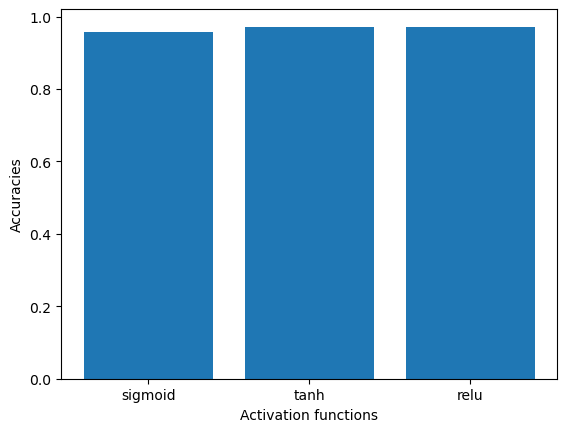

In [8]:
# Step VI : Plot Activations vs Accuracy
plt.bar(activations,accuracies)
plt.xlabel("Activation functions")
plt.ylabel("Accuracies")
plt.show()

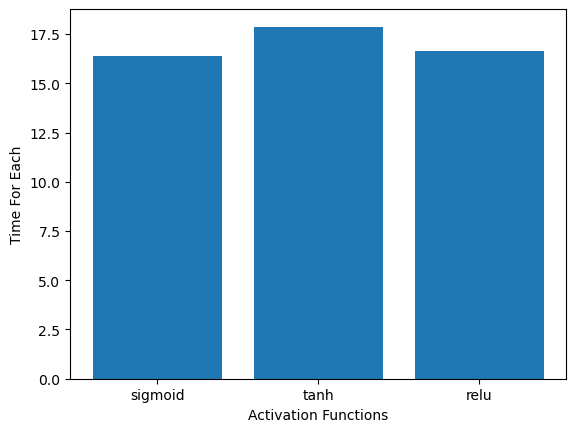

In [9]:
# Step VII : Plot Activations vs Time 
plt.bar(activations,times)
plt.xlabel("Activation Functions")
plt.ylabel("Time For Each")
plt.show()

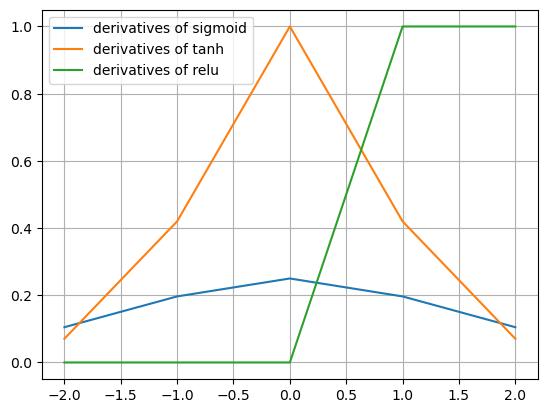

In [11]:
# Step VIII : Plot Gradient Flow
x = tf.constant([-2.0,-1.0,0.0,1.0,2.0])
s = tf.sigmoid(x)
t = tf.tanh(x)

plt.plot(x,s*(1-s),label='derivatives of sigmoid')
plt.plot(x,1-t**2,label='derivatives of tanh')
plt.plot(x,tf.cast(x>0,tf.float32),label='derivatives of relu')
plt.legend()
plt.grid()
plt.show()